<a href="https://colab.research.google.com/github/Muskan-Sh-23/Machine-learning/blob/main/Random_Forest/Random_Forest_Cross_Validation_using_Sklearn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forest Regression

In this notebook, I implement a Random Forest Regressor on the California Housing dataset.

The goal is to predict median house values and evaluate how well the Random Forest generalizes to unseen data.

I first build a baseline model, analyze its performance and overfitting, experiment with hyperparameters, and finally use cross-validation for more reliable model selection.

In [21]:
#Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import GridSearchCV

## 1. Dataset

The California Housing dataset is a regression dataset containing information about different California districts.

The target variable, `MedHouseVal`, represents the median house value in units of $100,000.

The dataset contains 20,640 samples and 8 input features.

In [22]:

# Load the California Housing dataset
data = fetch_california_housing()

# Separate the input features and target variable
X = data.data
y = data.target


print("Shape of X:", X.shape)
print("Shape of y:", y.shape)


print("Feature names:", data.feature_names)

print("Target:", data.target_names)

Shape of X: (20640, 8)
Shape of y: (20640,)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: ['MedHouseVal']


In [23]:

# Convert the dataset into a Pandas DataFrame
df = pd.DataFrame(X, columns=data.feature_names)

# Add the target variable as a separate column
df["MedHouseVal"] = y

# Display the first five rows as a formatted table
display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [24]:

# Display descriptive statistics in table format
display(df.describe())

# Display missing values in a readable table
display(df.isnull().sum().to_frame(name="Missing Values"))

# Display data types and non-null counts
df.info()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


,Missing Values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [25]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Check the dimensions of each split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (16512, 8)
X_test shape: (4128, 8)
y_train shape: (16512,)
y_test shape: (4128,)


In [26]:
# Create the Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth = 25,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1)

In [27]:
# Train the Random Forest on the training data
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [28]:
# # Create 5 folds and shuffle the data reproducibly
# kf = KFold(n_splits=5, shuffle=True, random_state=42)   # 5 fold cross-validtion

# # Evaluate the selected Random Forest using training data only
# cv_scores = cross_val_score(
#     RandomForestRegressor(
#         n_estimators=100,
#         max_depth=25,
#         min_samples_leaf=2,
#         random_state=42,
#         n_jobs=-1
#     ),
#     X_train,
#     y_train,
#     cv=kf,
#     scoring="r2",
#     n_jobs=1
# )

# # Display the R² score from each fold
# print("Cross-validation R² scores:", cv_scores)

# # Calculate average performance and variation
# print("Mean CV R²:", cv_scores.mean())
# print("Standard deviation:", cv_scores.std())

In [29]:

# Predict house values using the test dataset
y_pred = rf_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Values": y_test[:5],
    "Predicted Values": y_pred[:5]
})

display(comparison)

,Actual Values,Predicted Values
0,0.47700,0.491317
1,0.45800,0.729059
2,5.00001,4.889661
3,2.18600,2.551744
4,2.78000,2.342964


In [30]:

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

# Calculate R-squared (R²) score
r2 = r2_score(y_test, y_pred)

# Display the evaluation metrics
print("Random Forest Performance")
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

Random Forest Performance
MSE: 0.25445181908130104
RMSE: 0.5044321749068957
R² Score: 0.8058225917965866


In [31]:
# Predict the training data
y_train_pred = rf_model.predict(X_train)

# Calculate R² scores
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

# Calculate the gap between training and testing performance
r2_gap = train_r2 - test_r2

print("Training R²:", train_r2)
print("Testing R²:", test_r2)
print("R² Gap:", r2_gap)

Training R²: 0.9582871862234532
Testing R²: 0.8058225917965866
R² Gap: 0.15246459442686666


## Hyperparameter Tuning Using Cross-Validation

Cross-validation evaluates a model across multiple training and validation splits to obtain a more reliable estimate of its performance.

In this project, **GridSearchCV** is used to find the best hyperparameters for the Random Forest Regressor by testing different combinations of:

* `n_estimators`: Number of decision trees.
* `max_depth`: Maximum depth of each decision tree.
* `min_samples_leaf`: Minimum number of samples required in a leaf node.

Five-fold cross-validation is used to evaluate each combination using the mean R² score. The combination with the highest mean cross-validation R² is selected as the best configuration.


In [32]:
# Define the hyperparameter combinations to test
param_grid = {
    "n_estimators": [100],
    "max_depth": [20, 25],
    "min_samples_leaf": [1, 2, 5]
}

In [33]:
# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring="r2",
    n_jobs=1,
    verbose=2
)

# Train and compare the configurations
grid_search.fit(X_train, y_train)

# Display the best results
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation R²:", grid_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END .max_depth=20, min_samples_leaf=1, n_estimators=100; total time=  19.4s
[CV] END .max_depth=20, min_samples_leaf=1, n_estimators=100; total time=  15.2s
[CV] END .max_depth=20, min_samples_leaf=1, n_estimators=100; total time=  15.3s
[CV] END .max_depth=20, min_samples_leaf=1, n_estimators=100; total time=  15.2s
[CV] END .max_depth=20, min_samples_leaf=1, n_estimators=100; total time=  15.3s
[CV] END .max_depth=20, min_samples_leaf=2, n_estimators=100; total time=  13.7s
[CV] END .max_depth=20, min_samples_leaf=2, n_estimators=100; total time=  13.8s
[CV] END .max_depth=20, min_samples_leaf=2, n_estimators=100; total time=  14.1s
[CV] END .max_depth=20, min_samples_leaf=2, n_estimators=100; total time=  14.1s
[CV] END .max_depth=20, min_samples_leaf=2, n_estimators=100; total time=  13.6s
[CV] END .max_depth=20, min_samples_leaf=5, n_estimators=100; total time=  14.5s
[CV] END .max_depth=20, min_samples_leaf=5, n_est

In [34]:
# Create the final model using the best hyperparameters
rf_final = grid_search.best_estimator_

# Generate predictions on the test set
y_pred_final = rf_final.predict(X_test)

# Calculate evaluation metrics
final_mse = mean_squared_error(y_test, y_pred_final)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_final)

# Display final performance
print("Final Random Forest Performance")
print("Best Parameters:", grid_search.best_params_)
print("MSE:", final_mse)
print("RMSE:", final_rmse)
print("R² Score:", final_r2)

Final Random Forest Performance
Best Parameters: {'max_depth': 25, 'min_samples_leaf': 2, 'n_estimators': 100}
MSE: 0.254451819081301
RMSE: 0.5044321749068956
R² Score: 0.8058225917965867


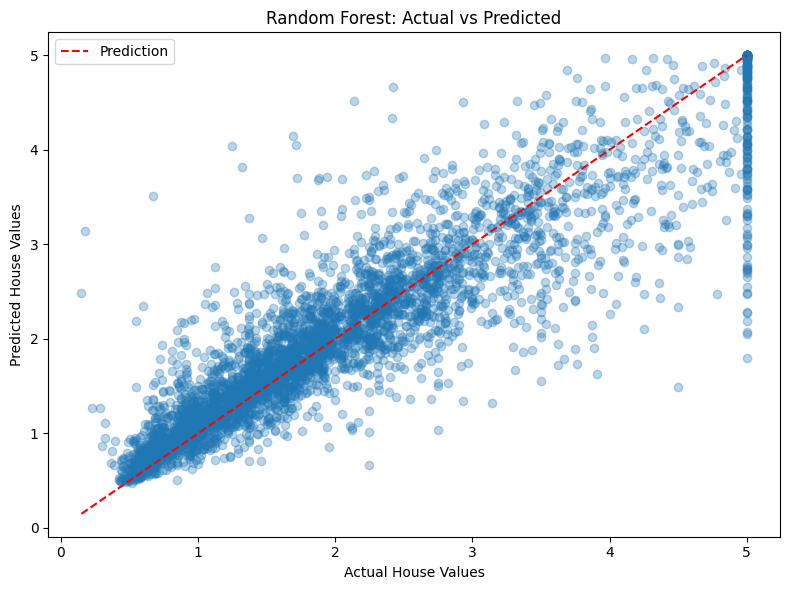

In [36]:
# Compare actual and predicted house values
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_final,
    alpha=0.3
)

# Line representing perfect predictions
min_val = min(y_test.min(), y_pred_final.min())
max_val = max(y_test.max(), y_pred_final.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Prediction"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

The final model achieved an **R² score of 0.8058**, an MSE of 0.25445, and an RMSE of 0.50443 on the test set. GridSearchCV selected the following hyperparameters:

* `n_estimators = 100`
* `max_depth = 25`
* `min_samples_leaf = 2`

The project demonstrated how cross-validation and systematic hyperparameter tuning can help select model configurations and evaluate generalization. The improvement over the baseline was small, showing that tuning does not always lead to substantial performance gains.

**Key takeaway:** Model performance should be evaluated using appropriate metrics, validation techniques, and evidence of generalization rather than training accuracy alone.
